In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split,RandomizedSearchCV
from sklearn.preprocessing import StandardScaler,LabelEncoder
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from xgboost import XGBRegressor

In [2]:
df= pd.read_csv("preprocessed_data.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,...,Competitor Pricing,Seasonality,Epidemic,Demand,Year,month,week_day,Final Price,Sales value,price to competitor
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,...,85.73,Winter,0,115,2022,1,5,69.084,7046.568,Low
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,...,92.02,Winter,0,229,2022,1,5,68.136,7971.912,Low
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,...,60.08,Winter,0,157,2022,1,5,56.646,6457.644,Low
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,...,85.19,Winter,0,52,2022,1,5,78.867,3549.015,Low
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,...,51.63,Winter,0,59,2022,1,5,54.410,3536.650,High


In [3]:
df.columns

Index(['Date', 'Store ID', 'Product ID', 'Category', 'Region',
       'Inventory Level', 'Units Sold', 'Units Ordered', 'Price', 'Discount',
       'Weather Condition', 'Promotion', 'Competitor Pricing', 'Seasonality',
       'Epidemic', 'Demand', 'Year', 'month', 'week_day', 'Final Price',
       'Sales value', 'price to competitor'],
      dtype='object')

In [4]:
features=['Store ID','Product ID','Category','Region','Price','Inventory Level',
          'Discount','Weather Condition', 'Promotion','Competitor Pricing','Seasonality',
       'Epidemic','Year','month','week_day']
target=["Demand"]

In [5]:
x=df[features].copy()
y=df[target]

In [6]:
x.dtypes

Store ID               object
Product ID             object
Category               object
Region                 object
Price                 float64
Inventory Level         int64
Discount                int64
Weather Condition      object
Promotion               int64
Competitor Pricing    float64
Seasonality            object
Epidemic                int64
Year                    int64
month                   int64
week_day                int64
dtype: object

In [7]:
cat_cols= x.select_dtypes(include="object").columns
cat_cols

Index(['Store ID', 'Product ID', 'Category', 'Region', 'Weather Condition',
       'Seasonality'],
      dtype='object')

In [8]:
for col in cat_cols:
    le= LabelEncoder()
    x[col]=le.fit_transform(x[col])

In [9]:
x.dtypes

Store ID                int64
Product ID              int64
Category                int64
Region                  int64
Price                 float64
Inventory Level         int64
Discount                int64
Weather Condition       int64
Promotion               int64
Competitor Pricing    float64
Seasonality             int64
Epidemic                int64
Year                    int64
month                   int64
week_day                int64
dtype: object

In [10]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2)

In [11]:
xgb= XGBRegressor(objective="reg:squarederror",n_jobs=-1)

In [12]:
param={
    "n_estimators":[200,300,500],
    "max_depth":[3,4,6,8],
    "learning_rate":[0.01,0.05,0.1],
    "subsample":[0.7,0.8,1.0],
    "colsample_bytree":[0.7,0.8,1.0],
    "min_child_weight":[1,3,5]
}

In [13]:
random_search=RandomizedSearchCV(
    estimator=xgb,
    param_distributions=param,
    n_iter=25,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=1,
    n_jobs=-1
)

In [14]:
random_search.fit(x_train,y_train)

Fitting 3 folds for each of 25 candidates, totalling 75 fits


,estimator,"XGBRegressor(...ree=None, ...)"
,param_distributions,"{'colsample_bytree': [0.7, 0.8, ...], 'learning_rate': [0.01, 0.05, ...], 'max_depth': [3, 4, ...], 'min_child_weight': [1, 3, ...], ...}"
,n_iter,25
,scoring,'neg_mean_absolute_error'
,n_jobs,-1
,refit,True
,cv,3
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [15]:
random_search.best_params_

{'subsample': 0.8,
 'n_estimators': 500,
 'min_child_weight': 5,
 'max_depth': 8,
 'learning_rate': 0.1,
 'colsample_bytree': 0.8}

In [16]:
best_model=random_search.best_estimator_

In [17]:
y_pred=best_model.predict(x_test)

In [18]:
mse=np.sqrt(mean_squared_error(y_test,y_pred))
r2= r2_score(y_test,y_pred)
mae=mean_absolute_error(y_test,y_pred)
print(mse, r2, mae)

9.22273649239764 0.9610852003097534 6.036489009857178


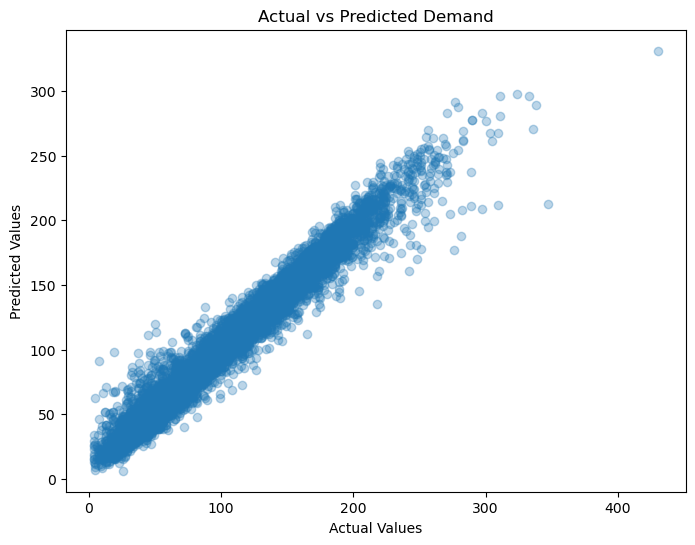

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted Demand")
plt.show()

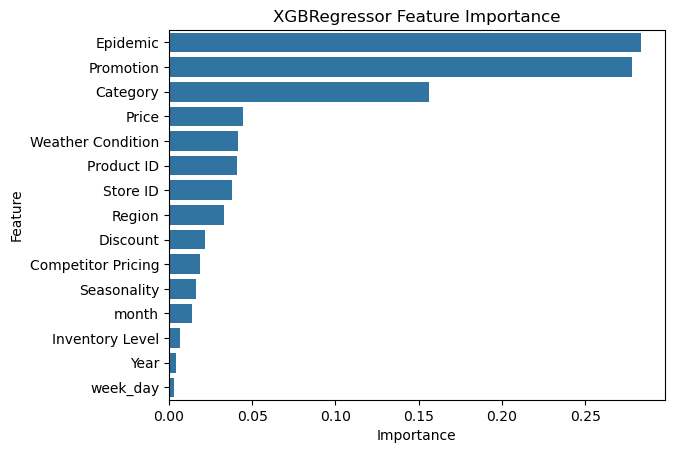

In [20]:
importance_df = pd.DataFrame({'Feature': x.columns,'Importance': best_model.feature_importances_})
importance_df = importance_df.sort_values(by='Importance', ascending=False)
sns.barplot(x='Importance', y='Feature', data=importance_df)
plt.title('XGBRegressor Feature Importance')
plt.show()